# Semantic segmentation on COCO val2017 (small training run)

# Parametrage GPU

In [3]:
import torch, os
print('CUDA available:', torch.cuda.is_available())
device = torch.device('cuda' if torch.cuda.is_available() else ('mps' if getattr(torch.backends, 'mps', None) and torch.backends.mps.is_available() else 'cpu'))
print('Device:', device)
if device.type == 'cuda':
    torch.backends.cudnn.benchmark = True
    print(torch.cuda.get_device_name(0))
os.makedirs('data/coco', exist_ok=True)


CUDA available: False
Device: cpu


# COCO Data Files

In [7]:
!pip -q install pycocotools
!wget -nc http://images.cocodataset.org/zips/val2017.zip -P data/coco
!wget -nc http://images.cocodataset.org/annotations/annotations_trainval2017.zip -P data/coco
!unzip -n data/coco/val2017.zip -d data/coco
!unzip -n data/coco/annotations_trainval2017.zip -d data/coco


# Tester les fichiers

In [10]:
import os, json, itertools

BASE = "data/coco"
VAL_DIR = f"{BASE}/val2017"
ANN_DIR = f"{BASE}/annotations"
VAL_JSON = f"{ANN_DIR}/instances_val2017.json"

val_count = sum(1 for f in os.scandir(VAL_DIR) if f.is_file() and f.name.endswith(".jpg")) if os.path.isdir(VAL_DIR) else 0
print("val2017 images on disk:", val_count)
print("val annotation JSON exists:", os.path.exists(VAL_JSON))

# paths used by the dataset
img_root = BASE
ann_file = VAL_JSON


val2017 images on disk: 5000
val annotation JSON exists: True


# Dataset COCODs

In [11]:
import os
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np
from pycocotools.coco import COCO
import torchvision.transforms.functional as TF

class cocoDs(Dataset):
    """
    COCO semantic segmentation from instance masks.
    Keeps original COCO category_id (background=0).
    Only uses images whose files actually exist on disk.
    """
    def __init__(self, img_root, ann_file, target_size=(128,128), limit=128):
        super().__init__()
        self.coco = COCO(ann_file)

        self.search_dirs = []
        if os.path.isdir(img_root):
            self.search_dirs.append(img_root)
        for d in [os.path.join(img_root, "val2017"),
                  os.path.join(img_root, "train2017")]:
            if os.path.isdir(d):
                self.search_dirs.append(d)

        img_ids = self.coco.getImgIds()
        if limit is not None:
            img_ids = img_ids[:int(limit)]

        self.items = []
        for img_id in img_ids:
            info = self.coco.loadImgs([img_id])[0]
            fname = info["file_name"]
            found = None
            for d in self.search_dirs:
                p = os.path.join(d, fname)
                if os.path.exists(p):
                    found = p
                    break
            if found is not None:
                self.items.append((img_id, found))

        self.target_size = target_size
        cats = self.coco.getCatIds()
        self._num_classes = (max(cats) + 1) if len(cats) else 1

        print(f"[cocoDs] usable images: {len(self.items)} | searched: {self.search_dirs}")

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        img_id, img_path = self.items[idx]
        img = Image.open(img_path).convert('RGB')
        w, h = img.size

        ann_ids = self.coco.getAnnIds(imgIds=[img_id], iscrowd=None)
        anns = self.coco.loadAnns(ann_ids)

        # out[ann['category_id']] = mask
        out = np.zeros((h, w), dtype=np.uint8)
        for ann in anns:
            if 'segmentation' not in ann:
                continue
            mask = self.coco.annToMask(ann).astype(bool)
            out[mask] = int(ann['category_id'])

        img = img.resize(self.target_size, Image.BILINEAR)
        mask_img = Image.fromarray(out, mode='L').resize(self.target_size, Image.NEAREST)

        x = TF.to_tensor(img)
        y = torch.from_numpy(np.array(mask_img, dtype=np.int64))
        return x, y

    @property
    def num_classes(self):
        return self._num_classes

# Training + Model + Loss

In [12]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.net(x)

class UNet(nn.Module):
    def __init__(self, in_ch=3, base_ch=32, num_classes=91):
        super().__init__()
        self.enc1 = DoubleConv(in_ch, base_ch)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = DoubleConv(base_ch, base_ch*2)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = DoubleConv(base_ch*2, base_ch*4)
        self.pool3 = nn.MaxPool2d(2)
        self.bot  = DoubleConv(base_ch*4, base_ch*8)
        self.up3  = nn.ConvTranspose2d(base_ch*8, base_ch*4, 2, stride=2)
        self.dec3 = DoubleConv(base_ch*8, base_ch*4)
        self.up2  = nn.ConvTranspose2d(base_ch*4, base_ch*2, 2, stride=2)
        self.dec2 = DoubleConv(base_ch*4, base_ch*2)
        self.up1  = nn.ConvTranspose2d(base_ch*2, base_ch, 2, stride=2)
        self.dec1 = DoubleConv(base_ch*2, base_ch)
        self.outc = nn.Conv2d(base_ch, num_classes, 1)
    def forward(self, x):
        x1 = self.enc1(x)
        x2 = self.enc2(self.pool1(x1))
        x3 = self.enc3(self.pool2(x2))
        xb = self.bot(self.pool3(x3))
        y = self.up3(xb); y = torch.cat([y, x3], dim=1); y = self.dec3(y)
        y = self.up2(y);  y = torch.cat([y, x2], dim=1); y = self.dec2(y)
        y = self.up1(y);  y = torch.cat([y, x1], dim=1); y = self.dec1(y)
        return self.outc(y)

def dice_loss_mc(logits, targets, eps=1e-6):
    C = logits.shape[1]
    probs = torch.softmax(logits, dim=1)
    tgt = F.one_hot(targets, num_classes=C).permute(0,3,1,2).float()
    num = 2 * (probs * tgt).sum(dim=(0,2,3))
    den = (probs.pow(2) + tgt.pow(2)).sum(dim=(0,2,3)) + eps
    return 1 - (num / den).mean()

def combined_loss(logits, targets, alpha=0.5):
    ce = F.cross_entropy(logits, targets)
    dl = dice_loss_mc(logits, targets)
    return alpha*ce + (1-alpha)*dl

@torch.no_grad()
def iou_and_pixel_acc(logits, targets):
    preds = logits.argmax(dim=1)
    total = targets.numel()
    correct = (preds == targets).sum().item()
    pixacc = correct / max(total, 1)
    C = logits.shape[1]
    ious = []
    for c in range(C):
        tp = ((preds == c) & (targets == c)).sum().item()
        fp = ((preds == c) & (targets != c)).sum().item()
        fn = ((preds != c) & (targets == c)).sum().item()
        denom = tp + fp + fn
        if denom > 0:
            ious.append(tp/denom)
    miou = sum(ious)/len(ious) if ious else 0.0
    return miou, pixacc

ds = cocoDs(img_root, ann_file, target_size=(128,128), limit=128)

num_classes = ds.num_classes
print('Images (usable):', len(ds), 'num_classes:', num_classes)

loader = DataLoader(ds, batch_size=8, shuffle=True, num_workers=0, pin_memory=(device.type=='cuda'))


model = UNet(in_ch=3, base_ch=32, num_classes=num_classes).to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

def train_steps(max_steps=40):
    model.train()
    it = iter(loader)
    tot, seen = 0.0, 0
    for step in range(max_steps):
        try:
            x, y = next(it)
        except StopIteration:
            it = iter(loader)
            x, y = next(it)
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        logits = model(x)
        loss = combined_loss(logits, y)
        loss.backward()
        opt.step()
        bs = x.size(0); tot += loss.item()*bs; seen += bs
        if (step+1) % 10 == 0:
            miou, pacc = iou_and_pixel_acc(logits, y)
            print(f'step {step+1:03d}/{max_steps}  loss={loss.item():.4f}  mIoU={miou:.3f}  pixAcc={pacc:.3f}')
    return tot/max(seen,1)

avg_loss = train_steps(max_steps=40)
print('done. avg_loss=', avg_loss)


loading annotations into memory...
Done (t=0.80s)
creating index...
index created!
[cocoDs] usable images: 128 | searched: ['data/coco', 'data/coco/val2017']
Images (usable): 128 num_classes: 91


step 010/40  loss=2.5846  mIoU=0.012  pixAcc=0.446
step 020/40  loss=2.4997  mIoU=0.011  pixAcc=0.491
step 030/40  loss=2.3757  mIoU=0.012  pixAcc=0.536
step 040/40  loss=2.2123  mIoU=0.016  pixAcc=0.546
done. avg_loss= 2.4740925252437593


# Visualisation

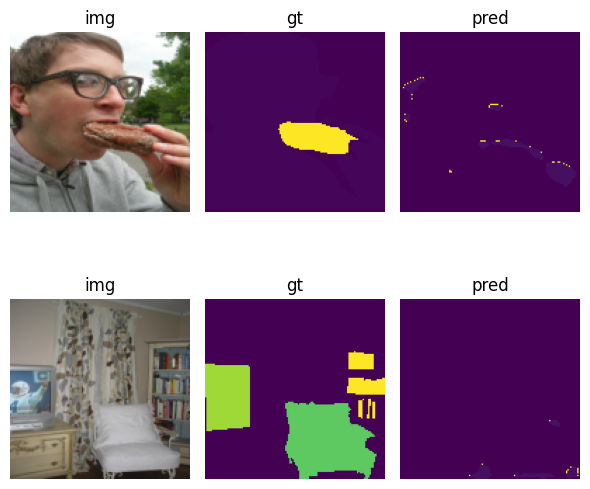

In [13]:
import matplotlib.pyplot as plt
@torch.no_grad()
def show_batch(n=2):
    model.eval()
    x, y = next(iter(loader))
    x, y = x[:n].to(device), y[:n].to(device)
    preds = model(x).argmax(dim=1)
    plt.figure(figsize=(6,3*n))
    for i in range(n):
        plt.subplot(n,3,3*i+1); plt.imshow(x[i].cpu().permute(1,2,0)); plt.axis('off'); plt.title('img')
        plt.subplot(n,3,3*i+2); plt.imshow(y[i].cpu()); plt.axis('off'); plt.title('gt')
        plt.subplot(n,3,3*i+3); plt.imshow(preds[i].cpu()); plt.axis('off'); plt.title('pred')
    plt.tight_layout(); plt.show()
show_batch(2)
